## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [ ]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Set the path to your dataset in Google Drive (edit the folder name below)
DATA_PATH = "/content/drive/MyDrive/heart+disease.zip"


## Cell 2 — Import Libraries

In [ ]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)


## Cell 3 — Load Dataset

In [ ]:
import zipfile
columns = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","target"]

with zipfile.ZipFile(DATA_PATH, "r") as z:
    files = z.namelist()
    dataset_file = None

    for file in files:
        if "processed.cleveland.data" in file:
            dataset_file = file
            break
    if dataset_file is None:
        for file in files:
            if file.endswith((".data", ".csv", ".txt")):
                dataset_file = file
                break

    print("\nLoading:", dataset_file)
    with z.open(dataset_file) as f:
        df = pd.read_csv(
            f,
            header=None,
            names=columns,
            na_values="?"
        )

print("\nDataset loaded successfully.")
print("Shape:", df.shape)

df.head()


Loading: processed.cleveland.data

Dataset loaded successfully.
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

In [ ]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nFirst 5 rows:")
display(df.head())
print("\nDescriptive statistics:")
display(df.describe())
print("\nTarget variable:")
print("Name:", "target")
print("Unique values:", df["target"].unique())


Shape: (303, 14)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Descriptive statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000



Target variable:
Name: target
Unique values: [0 2 1 3 4]


## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

Class counts:
target
0    164
1    139
Name: count, dtype: int64

Class percentages:
target
0    54.13
1    45.87
Name: proportion, dtype: float64


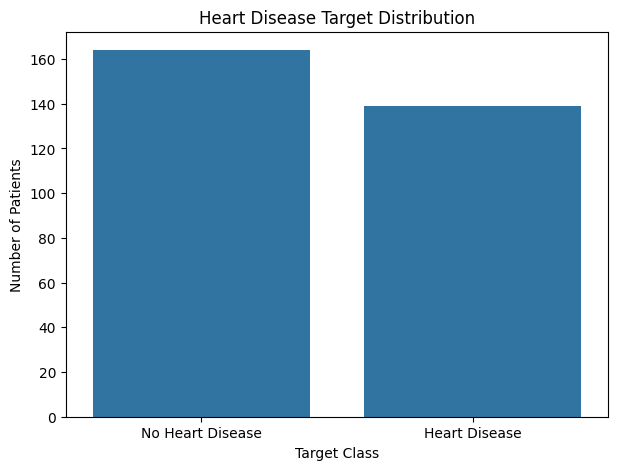

In [ ]:
# 0 = no heart disease
# 1 = presence of heart disease

df["target"] = pd.to_numeric(df["target"], errors="coerce")
df["target"] = (df["target"] > 0).astype(int)
class_counts = df["target"].value_counts().sort_index()
class_percentages = df["target"].value_counts(normalize=True).sort_index() * 100
print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages.round(2))

plt.figure(figsize=(7, 5))
sns.countplot(x="target",data=df)

plt.title("Heart Disease Target Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Patients")
plt.xticks([0, 1], ["No Heart Disease", "Heart Disease"])
plt.show()


### Interpretation

The dataset is somewhat imbalanced because the two target classes do not contain exactly the same number of samples. However, the imbalance is not extreme.
Because of this, accuracy alone should not be used to judge the models. Precision, recall, and F1-score should also be considered.

## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [ ]:
print("Missing values in each column:")
display(df.isnull().sum())
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())
print("\nData types:")
print(df.dtypes)
print("\nUnique values in each column:")
for column in df.columns:
    print(f"\n{column}:")
    print(df[column].unique())

Missing values in each column:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Number of duplicate rows:
0

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Unique values in each column:

age:
[63. 67. 37. 41. 56. 62. 57. 53. 44. 52. 48. 54. 49. 64. 58. 60. 50. 66.
 43. 40. 69. 59. 42. 55. 61. 65. 71. 51. 46. 45. 39. 68. 47. 34. 35. 29.
 70. 77. 38. 74. 76.]

sex:
[1. 0.]

cp:
[1. 4. 3. 2.]

trestbps:
[145. 160. 120. 130. 140. 172. 150. 110. 132. 117. 135. 112. 105. 124.
 125. 142. 128. 170. 155. 104. 180. 138. 108. 134. 122. 115. 118. 100.
 200.  94. 165. 102. 152. 101. 126. 174. 148. 178. 158. 192. 129. 144.
 123. 136. 146. 106. 156. 154. 114. 164.]

chol:
[233. 286. 229. 250. 204. 236. 268. 354. 254. 203. 192. 294. 256. 263.
 199. 168. 239. 275. 266. 211. 283. 284. 224. 206. 219. 340. 226. 247.
 167. 230. 

### Interpretation

The dataset contains missing values, mainly represented by `?` in the original file. These were converted to `NaN` while loading the dataset.
Missing values must be handled before training the models.
The dataset was also checked for duplicate rows and unusual values. Numerical columns will later be imputed using their median, while categorical columns will be imputed using their most frequent value.

## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

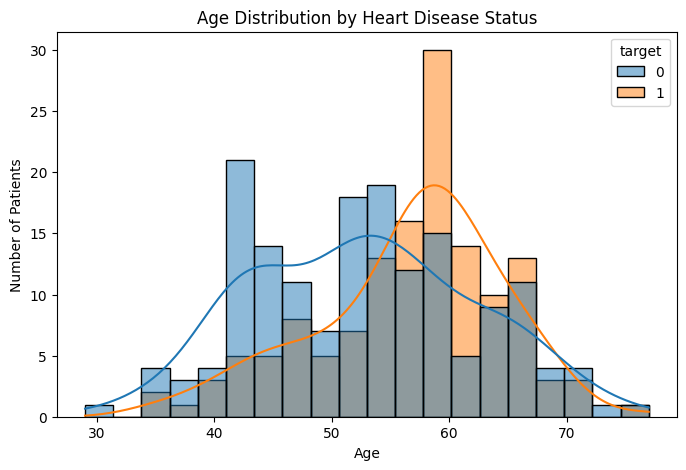

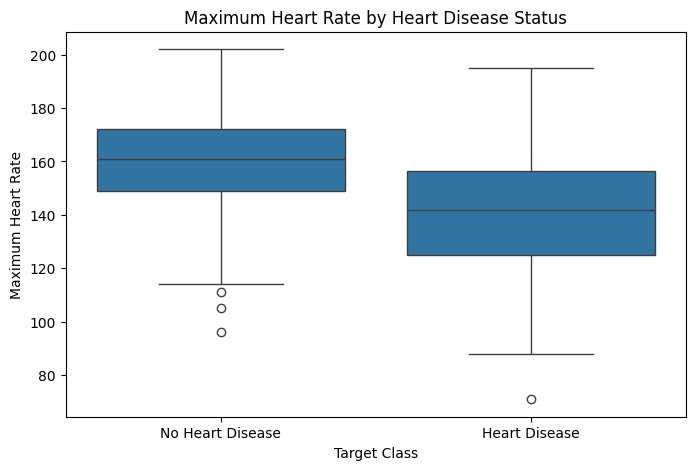

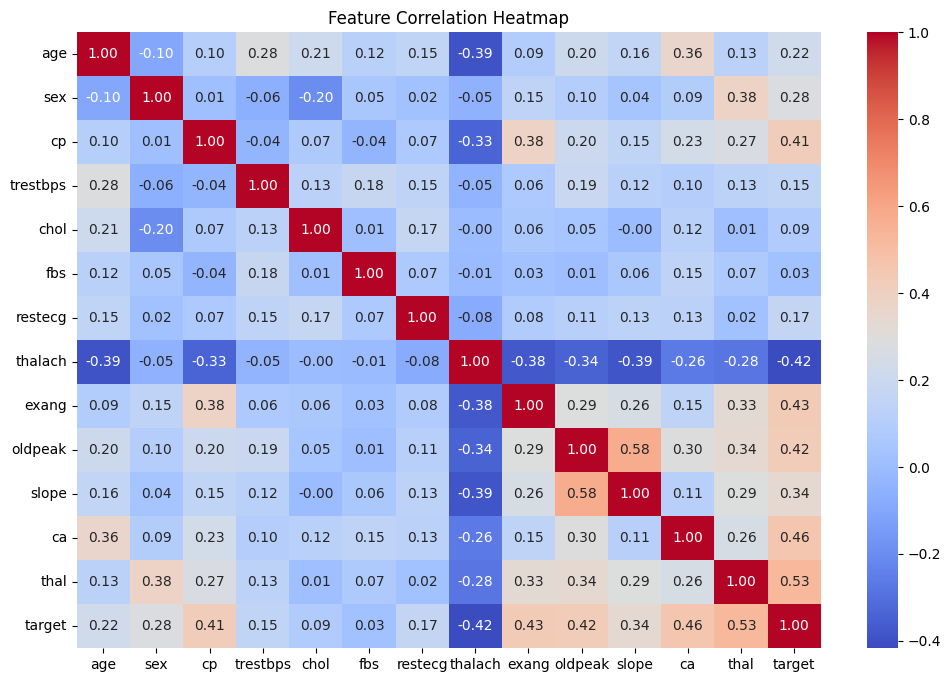

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df,x="age",hue="target",bins=20,kde=True)
plt.title("Age Distribution by Heart Disease Status")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df,x="target",y="thalach")
plt.title("Maximum Heart Rate by Heart Disease Status")
plt.xlabel("Target Class")
plt.ylabel("Maximum Heart Rate")
plt.xticks([0, 1],["No Heart Disease", "Heart Disease"])
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True),annot=True,fmt=".2f",cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()


### Visualization Interpretation

The age distribution shows that heart disease occurs across a range of ages, although its distribution differs between the two target classes.

The boxplot of maximum heart rate shows differences in the distribution of `thalach` between patients with and without heart disease.

The correlation heatmap provides an overview of relationships between numerical features. It also helps identify features that may contain useful information for classification.

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [ ]:
data = df.copy()
X = data.drop(columns=["target"])
y = data["target"]
categorical_features = ["sex","cp","fbs","restecg","exang","slope","ca","thal"]
numerical_features = ["age","trestbps","chol","thalach","oldpeak"]
print("Numerical features:")
print(numerical_features)
print("\nCategorical features:")
print(categorical_features)

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train,y_train,test_size=0.20,random_state=42,stratify=y_train)
print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
preprocessor = ColumnTransformer([("num", numeric_pipeline, numerical_features), ("cat", categorical_pipeline, categorical_features)])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)


print("\nProcessed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Numerical features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Training samples: 193
Validation samples: 49
Testing samples: 61

Processed training shape: (193, 28)
Processed validation shape: (49, 28)
Processed testing shape: (61, 28)


In [ ]:
import torch

X_train_tensor = torch.tensor(X_train_processed,dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_processed,dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_processed,dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_np,dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_np,dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_np,dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
val_dataset = TensorDataset(X_val_tensor,y_val_tensor)
test_dataset = TensorDataset(X_test_tensor,y_test_tensor)

train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)

print("DataLoaders created successfully.")

DataLoaders created successfully.


## Cell 9 — Design Your Own Neural Network

Design a neural network with **4-5 layers total** (input + hidden layers + output). Decide the number of neurons, hidden layers, and activation functions.

Fill in the table with your design:

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    |   32    |  ReLU      |
| Hidden 1 |   16    |  ReLU      |
| Hidden 2 |    8    |  ReLU      |
| Hidden 3 |    4    |  ReLU      |
| Output   |    1    |  Sigmoid   |



In [ ]:
X_train_processed.shape

(193, 28)

In [ ]:
input_dim = X_train_processed.shape[1]
hidden_1 = 32
hidden_2 = 16
hidden_3 = 8
output_dim = 1
print("Input dimension:", input_dim)

params_layer1 = (input_dim * hidden_1) + hidden_1
params_layer2 = (hidden_1 * hidden_2) + hidden_2
params_layer3 = (hidden_2 * hidden_3) + hidden_3
params_output = (hidden_3 * output_dim) + output_dim
total_parameters = (params_layer1+ params_layer2+ params_layer3+ params_output)
print("\nParameter calculation:")
print(f"Input -> 32: ({input_dim} × 32) + 32 = {params_layer1}")
print(f"32 -> 16: (32 × 16) + 16 = {params_layer2}")
print(f"16 -> 8: (16 × 8) + 8 = {params_layer3}")
print(f"8 -> 1: (8 × 1) + 1 = {params_output}")
print("\nTotal trainable parameters:", total_parameters)

Input dimension: 28

Parameter calculation:
Input -> 32: (28 × 32) + 32 = 928
32 -> 16: (32 × 16) + 16 = 528
16 -> 8: (16 × 8) + 8 = 136
8 -> 1: (8 × 1) + 1 = 9

Total trainable parameters: 1601


## Cell 11 — Implement Neural Network in PyTorch


In [ ]:
import torch
import torch.nn as nn

class MyModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1))

    def forward(self, x):
        return self.model(x)

input_dim = X_train_processed.shape[1]
model = MyModel(input_dim)

print(model)

MyModel(
  (model): Sequential(
    (0): Linear(in_features=28, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): ReLU()
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

## Loss Function

Binary Cross Entropy with Logits Loss 'BCEWithLogitsLoss' is appropriate because this is a binary classification problem.

It combines the sigmoid activation and binary cross-entropy loss into a single numerically stable function. The model therefore outputs a raw logit rather than applying sigmoid inside the network.

In [ ]:
loss_function = nn.BCEWithLogitsLoss()
print(loss_function)

BCEWithLogitsLoss()


## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

I selected the Adam optimizer because it adapts the learning rate for each parameter and generally works well for training neural networks.
It also requires less manual learning-rate tuning than basic gradient descent.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## Cell 14 — Compile the Model

## Model Preparation

In PyTorch, the model is prepared by defining the loss function and optimizer rather than using a separate compilation step.
The model, loss function, and optimizer are now ready for training.

In [ ]:
num_epochs = 100
history = {"train_loss": [], "val_loss": []}

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch).squeeze(1)
        loss = loss_function(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * X_batch.size(0)
    train_loss = (running_train_loss / len(train_loader.dataset))

    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch).squeeze(1)
            loss = loss_function(outputs,y_batch)
            running_val_loss += (loss.item() * X_batch.size(0))

    val_loss = (running_val_loss / len(val_loader.dataset))
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch + 1}/{num_epochs}]\nTrain Loss: {train_loss:.4f}\nValidation Loss: {val_loss:.4f}")

Epoch [10/100]
Train Loss: 0.6274
Validation Loss: 0.6111
Epoch [20/100]
Train Loss: 0.4013
Validation Loss: 0.3737
Epoch [30/100]
Train Loss: 0.3461
Validation Loss: 0.2970
Epoch [40/100]
Train Loss: 0.3207
Validation Loss: 0.2936
Epoch [50/100]
Train Loss: 0.3015
Validation Loss: 0.3120
Epoch [60/100]
Train Loss: 0.2896
Validation Loss: 0.3030
Epoch [70/100]
Train Loss: 0.2666
Validation Loss: 0.3215
Epoch [80/100]
Train Loss: 0.2553
Validation Loss: 0.3436
Epoch [90/100]
Train Loss: 0.2273
Validation Loss: 0.3621
Epoch [100/100]
Train Loss: 0.2124
Validation Loss: 0.3505


## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

## Training and Validation Loss

The training and validation losses are plotted against the number of epochs to observe how the model learns.
If training loss continues decreasing while validation loss starts increasing, this can indicate overfitting. If both losses decrease and remain relatively close, the model is learning without a strong indication of overfitting.

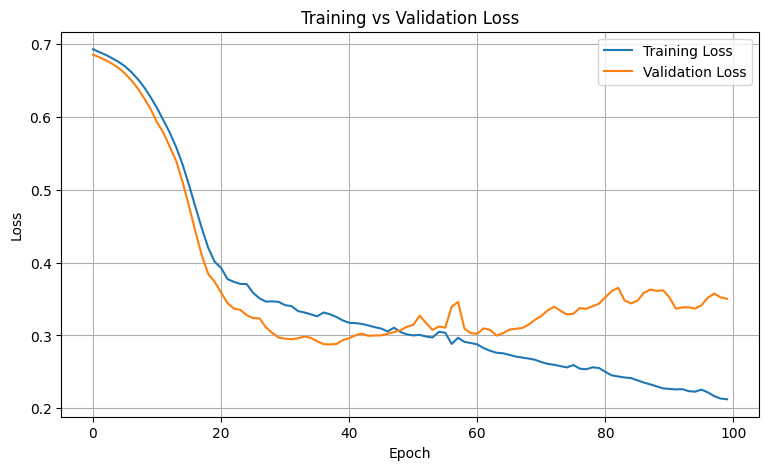

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(history["train_loss"],label="Training Loss")
plt.plot(history["val_loss"],label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.



The trained neural network is evaluated on the test set using accuracy, precision, recall, and F1-score.

The test set was kept separate during training and preprocessing, so it provides an estimate of how the model performs on unseen data.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
model.eval()
y_true = []
y_prob = []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = model(X_batch).squeeze(1)
        probabilities = torch.sigmoid(outputs)
        y_prob.extend(probabilities.cpu().numpy())
        y_true.extend(y_batch.cpu().numpy())

threshold = 0.5
y_pred_nn = [1 if probability >= threshold else 0 for probability in y_prob]

nn_accuracy = accuracy_score(y_true,y_pred_nn)
nn_precision = precision_score(y_true,y_pred_nn,zero_division=0)
nn_recall = recall_score(y_true,y_pred_nn,zero_division=0)
nn_f1 = f1_score(y_true,y_pred_nn,zero_division=0)

print("Neural Network Results")
print("----------------------")
print(f"Accuracy : {nn_accuracy:.4f}")
print(f"Precision: {nn_precision:.4f}")
print(f"Recall   : {nn_recall:.4f}")
print(f"F1-score : {nn_f1:.4f}")

Neural Network Results
----------------------
Accuracy : 0.9344
Precision: 0.9000
Recall   : 0.9643
F1-score : 0.9310


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [ ]:
ada_model = AdaBoostClassifier(n_estimators=100,learning_rate=0.5,random_state=42)
ada_model.fit(X_train_processed,y_train_np)
y_pred_ada = ada_model.predict(X_test_processed)
ada_accuracy = accuracy_score(y_test_np,y_pred_ada)
ada_precision = precision_score(y_test_np,y_pred_ada,zero_division=0)
ada_recall = recall_score(y_test_np,y_pred_ada,zero_division=0)
ada_f1 = f1_score(y_test_np,y_pred_ada,zero_division=0)

print(f"Accuracy : {ada_accuracy:.4f}")
print(f"Precision: {ada_precision:.4f}")
print(f"Recall   : {ada_recall:.4f}")
print(f"F1-score : {ada_f1:.4f}")

Accuracy : 0.9016
Precision: 0.8667
Recall   : 0.9286
F1-score : 0.8966


## Cell 19 — Compare Both Models

Fill in your results:

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network |   0.9344 | 0.9000    | 0.9643 | 0.9310   |
| AdaBoost       |   0.9016 | 0.8667    | 0.9286 | 0.8966   |


In [ ]:
comparison = pd.DataFrame({"Model": ["Neural Network","AdaBoost"],
"Accuracy": [nn_accuracy,ada_accuracy],
"Precision": [nn_precision,ada_precision],
"Recall": [nn_recall,ada_recall],
"F1-Score": [nn_f1,ada_f1]})

display(comparison.style.format({"Accuracy": "{:.4f}","Precision": "{:.4f}","Recall": "{:.4f}","F1-Score": "{:.4f}"}))

,Model,Accuracy,Precision,Recall,F1-Score
0,Neural Network,0.9344,0.9000,0.9643,0.9310
1,AdaBoost,0.9016,0.8667,0.9286,0.8966


## Cell 20 — Final Interpretation

### 1. Dataset Balance

The target classes are not perfectly balanced. There are different numbers of samples belonging to the two classes, although the imbalance is not extreme. Therefore, accuracy alone is not sufficient for evaluating the classifiers, and precision, recall, and F1-score were also considered.

### 2. Preprocessing

Several preprocessing steps were necessary before training the models. Missing values were handled using median imputation for numerical features and most-frequent imputation for categorical features. Numerical features were standardized using StandardScaler, while categorical features were converted into numerical representations using one-hot encoding.

The data was also divided into training, validation, and test sets. The preprocessing transformer was fitted only on the training data to avoid data leakage.

### 3. Neural Network

A feed-forward neural network with three hidden layers was implemented using PyTorch. The hidden layers use ReLU activation functions, while the final layer produces a single logit for binary classification.

BCEWithLogitsLoss was selected as the loss function because it is appropriate for binary classification and combines sigmoid activation with binary cross-entropy in a numerically stable manner. Adam was selected as the optimizer.

The training and validation loss curves were used to monitor the learning process and identify possible overfitting.

### 4. AdaBoost

AdaBoost was implemented as a second classification method. It uses an ensemble of weak learners and gives greater importance to samples that previous learners classified incorrectly.

### 5. Model Comparison

The two models were evaluated using accuracy, precision, recall, and F1-score.

The numerical results obtained from the test set are shown in the comparison table above. These metrics provide different perspectives on model performance, particularly because the dataset is not perfectly balanced.

The final comparison should therefore consider all four metrics rather than relying on accuracy alone.